# Complete Analysis of the Results of Qwen 3.5 0.8B Procedural Schema Distillation Using LoRA Fine-Tuning
### Prerequisites
<b>Student:</b> Qwen 3.5 0.8B<br>
<b>Teacher:</b> Qwen 3.5 9B<br>
<b>Local Models Host:</b> Ollama<br>
<b>Fine-Tuning Pipeline:</b> Unsloth<br>
<b>Baseline Results:</b><br>
Qwen 3.5 0.8B       | Valid SQL:  50.50% (153/303) | Avg Latency:  209.2 ms | Errors: {'syntax_error': 1, 'no_such_column': 108, 'no_such_table': 1, 'other_error': 40}<br>
Qwen 3.5 9B         | Valid SQL:  84.49% (256/303) | Avg Latency:  601.0 ms | Errors: {'syntax_error': 0, 'no_such_column': 20, 'no_such_table': 0, 'other_error': 27}<br>
<b>Original Dataset:</b> b-mc2/sql-create-context (Hugging Face)<br>
### Observations and Goal
As shown by the initial error analysis on 303 unseen schemas, 72% of the 0.8B model's failures were `no_such_column` during multi-table JOINs.<br>
<b>Goal:</b> Fine-Tune Qwen 3.5 0.8B to effectively handle valid SQL execution while maintaining low VRAM usage and low latency. Since the model mostly struggles with multi-table relations, the distilled dataset will only include schemas with 2+ tables.
### Datasets
Cleaned up the original dataset to only include schemas that require at least one JOIN operation.<br>
<b>Pruned Dataset Size:</b> 2001 rows (Schema + Question + Gold SQL) | 1771 unique 2+ table schemas<br>
<b>Train/Test Split:</b> 85/15<br>
<b>Split Summary:</b><br>
Train Pool: 1698 rows across 1505 unique schemas<br>
Test Pool:  303 rows across 266 unique schemas <br>
<b>Dataset Distillation:</b><br>
Unique verified training examples: 1430<br>
True total rejected across all 1,698 rows: 268<br>
<b>Distilled Dataset Location:</b> data/distilled_train.jsonl

<b>Imports and Inits</b>

In [26]:
import json
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

ROOT_DIR = Path.cwd().parent
DATA_DIR = ROOT_DIR / "data"

with open(DATA_DIR / "eval_results.json", "r", encoding="utf-8") as f:
    eval_results = list(json.load(f).values())

with open(DATA_DIR / "training_loss_log.json", "r", encoding="utf-8") as f:
    loss_history = json.load(f)


<b>Comparison of Average Final Accuracies Between the Models</b>

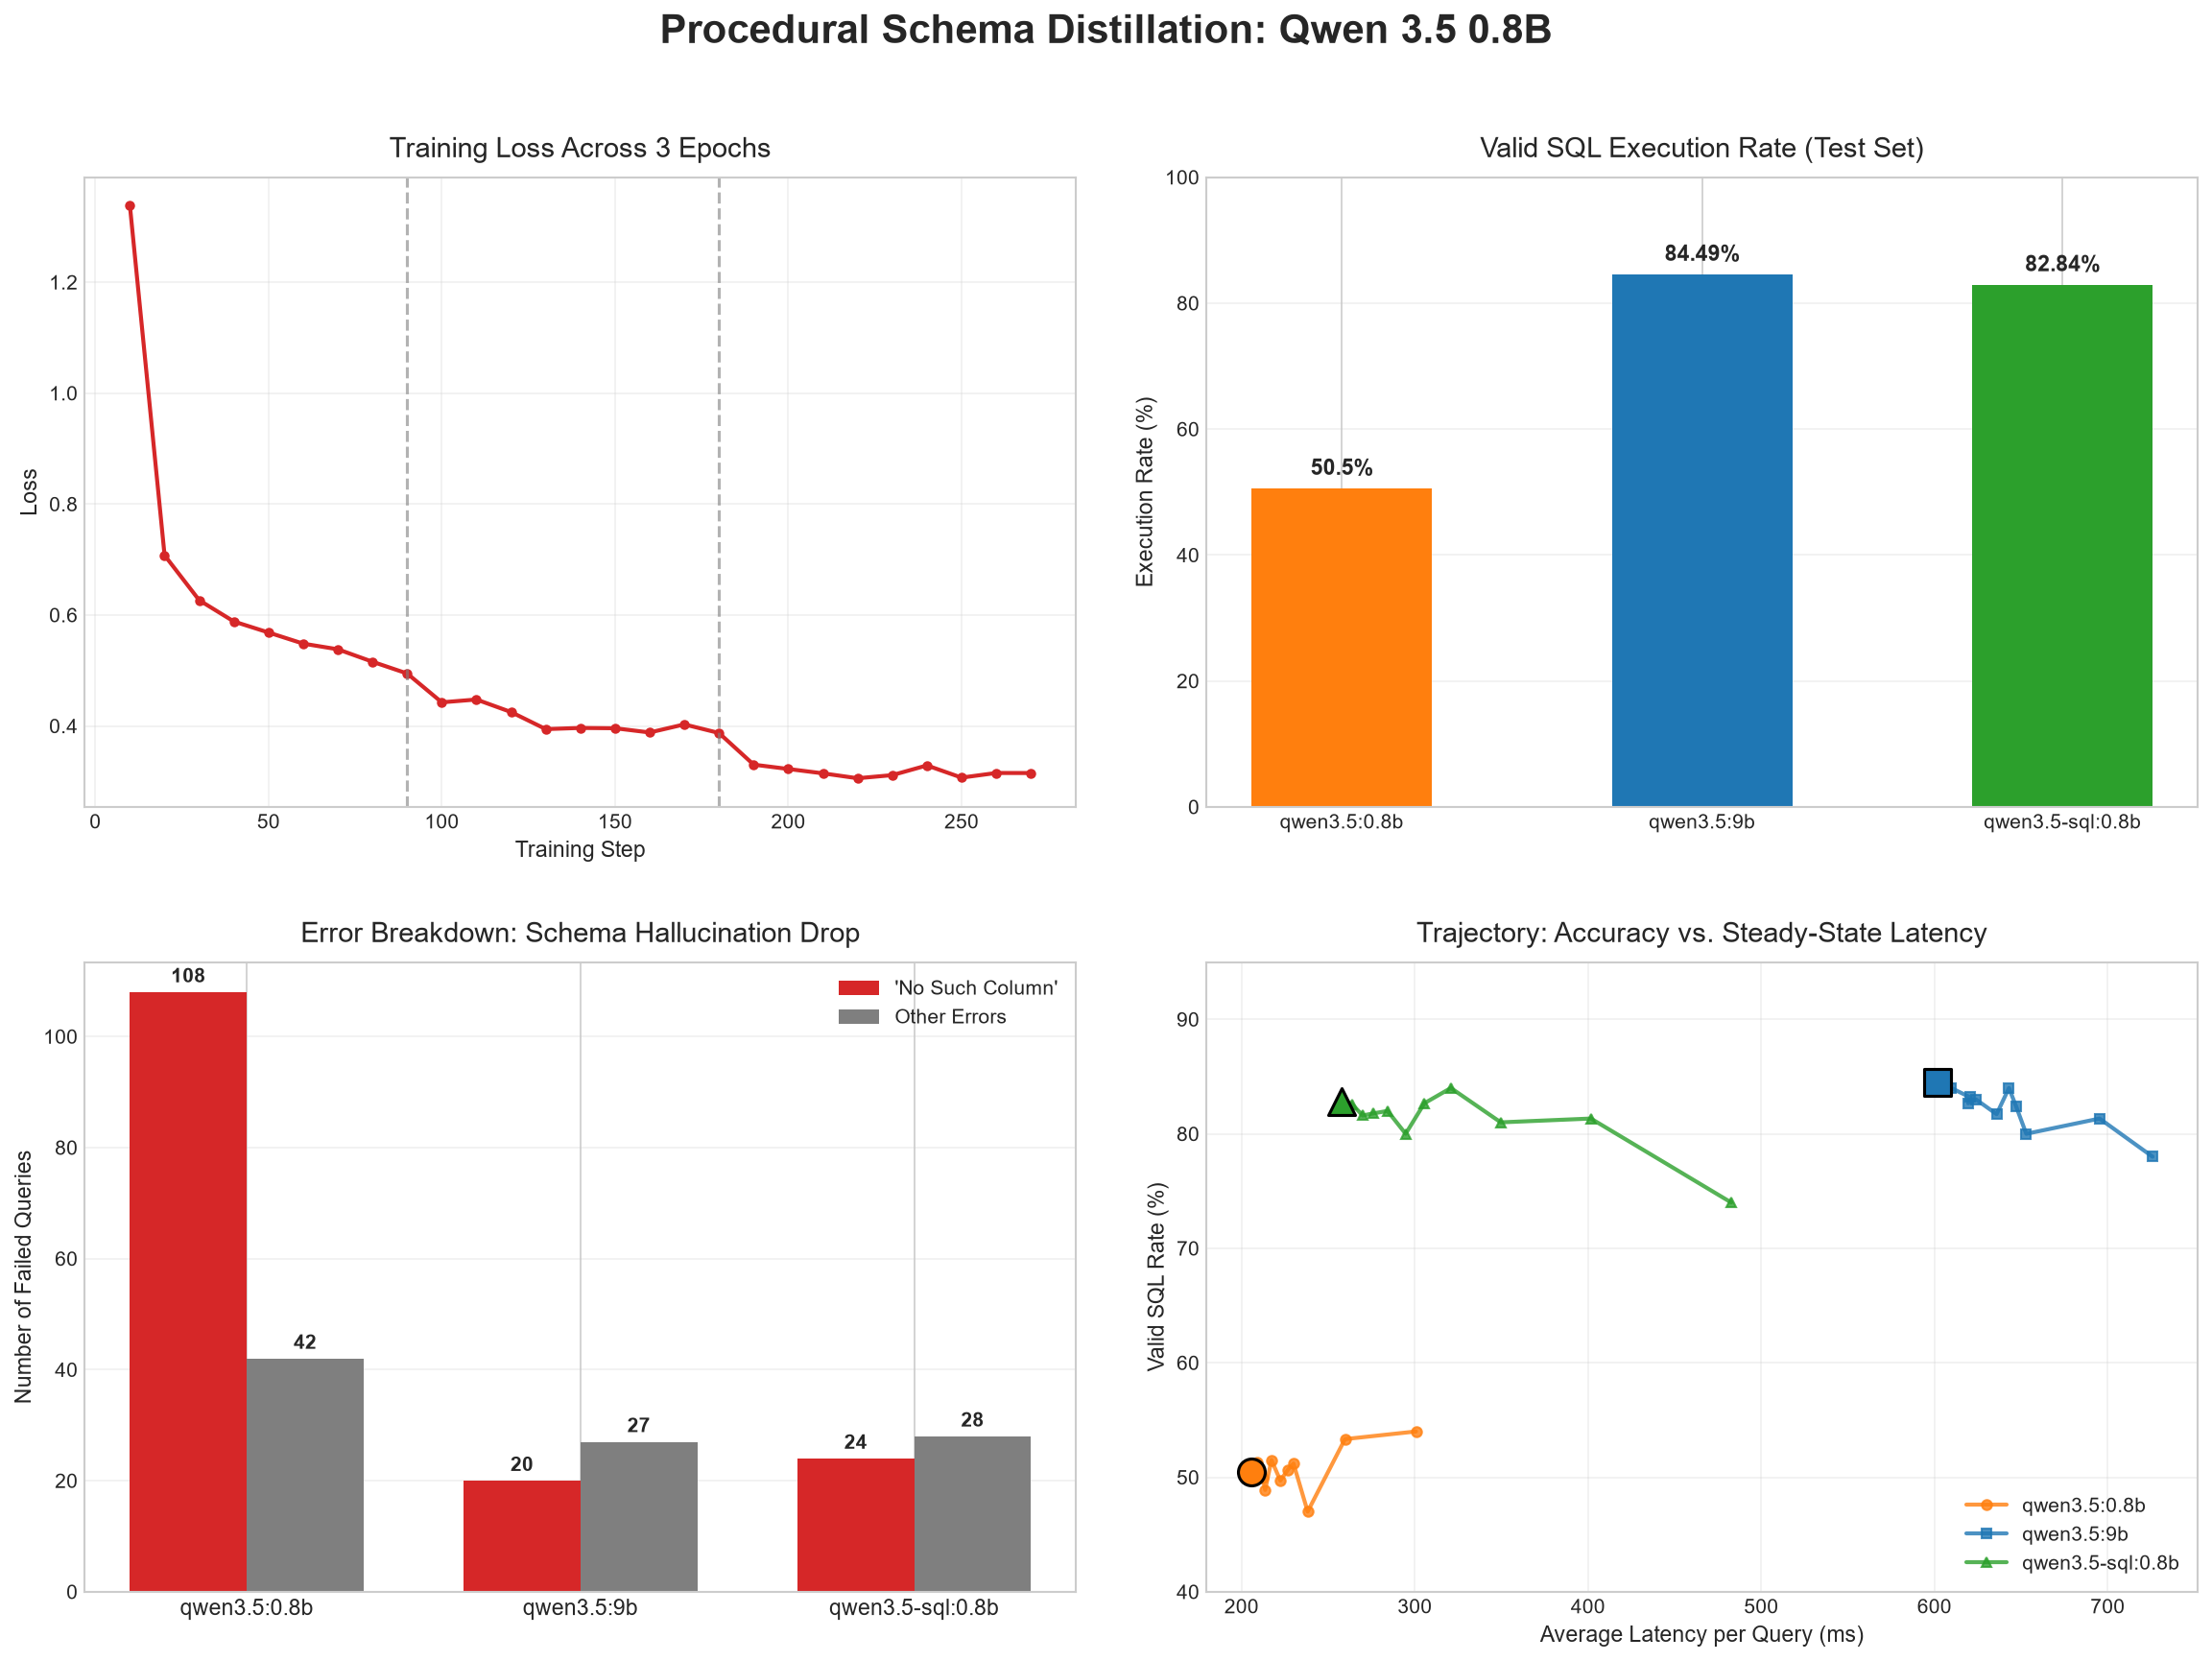

In [27]:
# Fig Setup
fig = plt.figure(figsize=(16, 12), dpi=150)
plt.style.use("seaborn-v0_8-whitegrid")
fig.suptitle("Procedural Schema Distillation: Qwen 3.5 0.8B", fontsize=20, fontweight='bold', y=0.98)

colors = {"qwen3.5:0.8b": "tab:orange", "qwen3.5:9b": "tab:blue", "qwen3.5-sql:0.8b": "tab:green"}
markers = {"qwen3.5:0.8b": "o", "qwen3.5:9b": "s", "qwen3.5-sql:0.8b": "^"}
model_names = [x["model"] for x in eval_results]

# Top left subplot (Loss Curve)
ax1 = plt.subplot(2, 2, 1)
steps = [x["step"] for x in loss_history]
losses = [x["loss"] for x in loss_history]

ax1.plot(steps, losses, marker="o", markersize=4, color="tab:red", linewidth=2)
ax1.axvline(x=90, color="gray", linestyle="--", alpha=0.6)
ax1.axvline(x=180, color="gray", linestyle="--", alpha=0.6)
ax1.set_title("Training Loss Across 3 Epochs", fontsize=14, pad=10)
ax1.set_xlabel("Training Step", fontsize=11)
ax1.set_ylabel("Loss", fontsize=11)
ax1.grid(True, alpha=0.3)

# Top right subplot (Accuracy)
ax2 = plt.subplot(2, 2, 2)
accuracies = [x["execution_valid_pct"] for x in eval_results]

bars = ax2.bar(model_names, accuracies, color=["tab:orange", "tab:blue", "tab:green"], width=0.5)
for bar in bars:
    height = bar.get_height()
    ax2.text(bar.get_x() + bar.get_width() / 2, height + 1.5, f"{height}%", 
             ha="center", va="bottom", fontsize=11, fontweight="bold")

ax2.set_title("Valid SQL Execution Rate (Test Set)", fontsize=14, pad=10)
ax2.set_ylabel("Execution Rate (%)", fontsize=11)
ax2.set_ylim(0, 100)
ax2.grid(axis="y", alpha=0.3)

# Bottom left subplot (Column Error Reduction)
ax3 = plt.subplot(2, 2, 3)
no_such_col_errors = [x["errors_breakdown"]["no_such_column"] for x in eval_results]
other_errors = [
    x["errors_breakdown"]["syntax_error"] + 
    x["errors_breakdown"]["no_such_table"] + 
    x["errors_breakdown"]["other_error"] 
    for x in eval_results
]

x_indexes = np.arange(len(model_names))
width = 0.35

bars1 = ax3.bar(x_indexes - width/2, no_such_col_errors, width, label="'No Such Column'", color="tab:red")
bars2 = ax3.bar(x_indexes + width/2, other_errors, width, label="Other Errors", color="tab:gray")

for bar in bars1 + bars2:
    height = bar.get_height()
    ax3.text(bar.get_x() + bar.get_width()/2, height + 1, str(int(height)), ha='center', va='bottom', fontweight='bold')

ax3.set_title("Error Breakdown: Schema Hallucination Drop", fontsize=14, pad=10)
ax3.set_xticks(x_indexes)
ax3.set_xticklabels(model_names, fontsize=11)
ax3.set_ylabel("Number of Failed Queries", fontsize=11)
ax3.legend(fontsize=10)
ax3.grid(axis="y", alpha=0.3)

# Bottom right subplot (Eval Trajectory)
ax4 = plt.subplot(2, 2, 4)

for info in eval_results:
    model_name = info["model"]
    # remove the Ollama cold-start loading spike
    lats = info["cont_lats"][1:]
    accs = info["cont_accs"][1:]
    
    ax4.plot(lats, accs, marker=markers.get(model_name), color=colors.get(model_name), 
             linewidth=2, markersize=5, alpha=0.8, label=f"{model_name}")
    
    ax4.scatter(info["avg_latency_ms"], info["execution_valid_pct"], 
                color=colors.get(model_name), s=180, zorder=5, marker=markers.get(model_name),
                edgecolors='black', linewidths=1.5)

ax4.set_title("Trajectory: Accuracy vs. Steady-State Latency", fontsize=14, pad=10)
ax4.set_xlabel("Average Latency per Query (ms)", fontsize=11)
ax4.set_ylabel("Valid SQL Rate (%)", fontsize=11)
ax4.set_ylim(40, 95)
ax4.grid(True, alpha=0.3)
ax4.legend(loc='lower right', fontsize=10)

plt.tight_layout(pad=3.0)
plt.savefig(ROOT_DIR / "assets/distillation_dashboard.png", bbox_inches='tight')
plt.show()